In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load Iris dataset
from sklearn.datasets import load_iris

iris = load_iris()

# Create DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add actual flower labels
df["Species"] = iris.target

# Display first 5 rows
print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   Species  
0        0  
1        0  
2        0  
3        0  
4        0  


In [2]:
# Dataset dimensions
print("Dataset shape:", df.shape)

# Column information
print("\nDataset information:")
df.info()

# Statistical summary
print("\nStatistical summary:")
print(df.describe())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (150, 5)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   Species            150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB

Statistical summary:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000          

In [3]:
# Separate input features
X = df.drop("Species", axis=1)

# Store actual species labels
y = df["Species"]

print("Features shape:", X.shape)
print("Labels shape:", y.shape)

print("\nInput features:")
print(X.head())

print("\nActual labels:")
print(y.head())

Features shape: (150, 4)
Labels shape: (150,)

Input features:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Actual labels:
0    0
1    0
2    0
3    0
4    0
Name: Species, dtype: int64


In [4]:
from sklearn.preprocessing import StandardScaler

# Create scaler object
scaler = StandardScaler()

# Scale the input features
X_scaled = scaler.fit_transform(X)

# Convert scaled data into DataFrame
X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

print(X_scaled.head())

print("\nMean of scaled features:")
print(X_scaled.mean())

print("\nStandard deviation:")
print(X_scaled.std())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0          -0.900681          1.019004          -1.340227         -1.315444
1          -1.143017         -0.131979          -1.340227         -1.315444
2          -1.385353          0.328414          -1.397064         -1.315444
3          -1.506521          0.098217          -1.283389         -1.315444
4          -1.021849          1.249201          -1.340227         -1.315444

Mean of scaled features:
sepal length (cm)   -1.690315e-15
sepal width (cm)    -1.842970e-15
petal length (cm)   -1.698641e-15
petal width (cm)    -1.409243e-15
dtype: float64

Standard deviation:
sepal length (cm)    1.00335
sepal width (cm)     1.00335
petal length (cm)    1.00335
petal width (cm)     1.00335
dtype: float64


In [5]:
from sklearn.cluster import KMeans

wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

print("WCSS values:")
print(wcss)

WCSS values:
[600.0, 222.36170496502302, 139.82049635974974, 114.09254690403094, 90.92751382392049, 81.54439095511782, 72.6311438266719, 62.540605695781245, 55.119492805290584, 47.39103517634709]


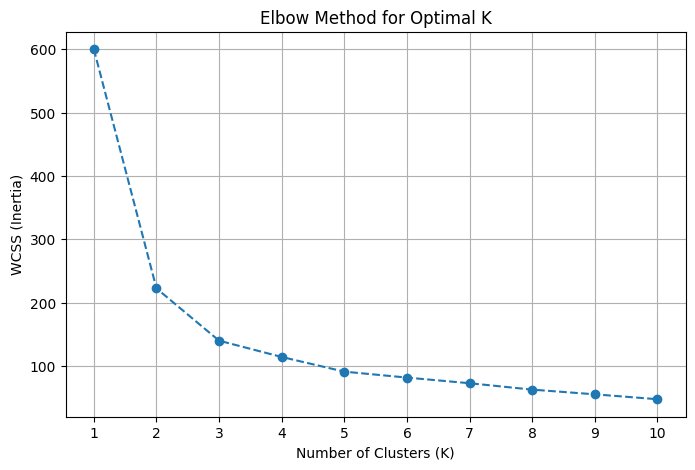

In [6]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker="o",
    linestyle="--"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.title("Elbow Method for Optimal K")

plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [7]:
from sklearn.cluster import KMeans

# Create K-Means model
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Train the model and assign clusters
clusters = kmeans.fit_predict(X_scaled)

# Add predicted clusters to DataFrame
df["Predicted_Cluster"] = clusters

print("K-Means clustering completed!")

print("\nCluster assignments:")
print(df[["Species", "Predicted_Cluster"]].head(10))

print("\nCluster counts:")
print(df["Predicted_Cluster"].value_counts().sort_index())

K-Means clustering completed!

Cluster assignments:
   Species  Predicted_Cluster
0        0                  1
1        0                  1
2        0                  1
3        0                  1
4        0                  1
5        0                  1
6        0                  1
7        0                  1
8        0                  1
9        0                  1

Cluster counts:
Predicted_Cluster
0    53
1    50
2    47
Name: count, dtype: int64


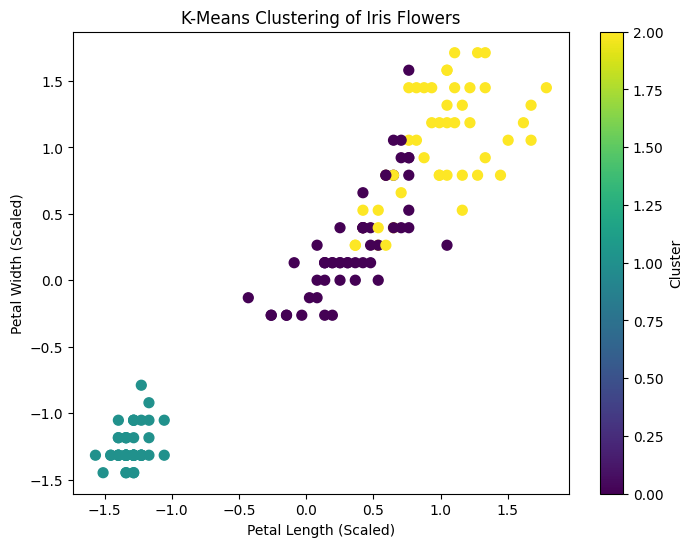

In [8]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled["petal length (cm)"],
    X_scaled["petal width (cm)"],
    c=clusters,
    cmap="viridis",
    s=50
)

plt.xlabel("Petal Length (Scaled)")
plt.ylabel("Petal Width (Scaled)")
plt.title("K-Means Clustering of Iris Flowers")

plt.colorbar(label="Cluster")
plt.show()

In [9]:
# Create a comparison table
comparison = pd.crosstab(
    y,
    clusters,
    rownames=["Actual Species"],
    colnames=["Predicted Cluster"]
)

print(comparison)

Predicted Cluster   0   1   2
Actual Species               
0                   0  50   0
1                  39   0  11
2                  14   0  36


In [10]:
from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(y, clusters)

print("Adjusted Rand Index:", round(ari, 4))

Adjusted Rand Index: 0.6201


In [11]:
from sklearn.decomposition import PCA

# Create PCA object with 2 components
pca = PCA(n_components=2)

# Apply PCA to scaled features
X_pca = pca.fit_transform(X_scaled)

# Convert PCA results into DataFrame
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

print("Original shape:", X_scaled.shape)
print("PCA shape:", pca_df.shape)

print("\nFirst 5 PCA rows:")
print(pca_df.head())

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal explained variance:")
print(pca.explained_variance_ratio_.sum())

Original shape: (150, 4)
PCA shape: (150, 2)

First 5 PCA rows:
        PC1       PC2
0 -2.264703  0.480027
1 -2.080961 -0.674134
2 -2.364229 -0.341908
3 -2.299384 -0.597395
4 -2.389842  0.646835

Explained variance ratio:
[0.72962445 0.22850762]

Total explained variance:
0.9581320720000166


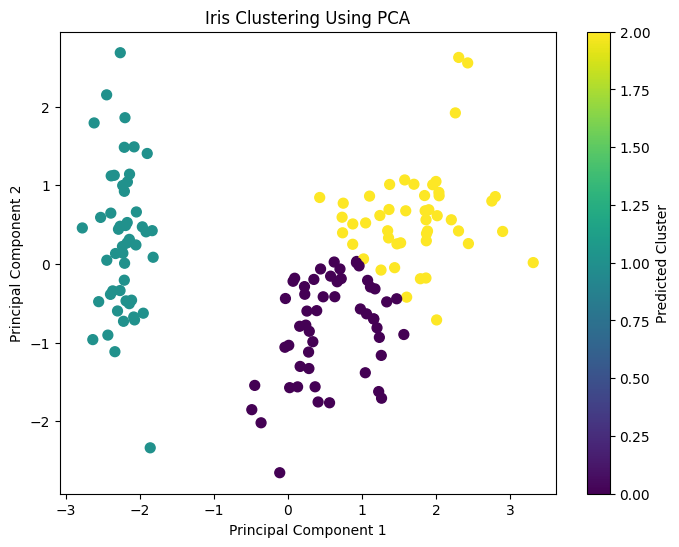

In [12]:
plt.figure(figsize=(8, 6))

plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=clusters,
    cmap="viridis",
    s=50
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Iris Clustering Using PCA")

plt.colorbar(label="Predicted Cluster")
plt.show()

In [13]:
import joblib

# Save trained models
joblib.dump(kmeans, "iris_kmeans_model.pkl")
joblib.dump(scaler, "iris_scaler.pkl")

print("Models saved successfully!")

Models saved successfully!


In [14]:
# Load saved models
loaded_kmeans = joblib.load("iris_kmeans_model.pkl")
loaded_scaler = joblib.load("iris_scaler.pkl")

print("Models loaded successfully!")

Models loaded successfully!


In [15]:
# New flower measurements
new_flower = [[5.1, 3.5, 1.4, 0.2]]

# Scale the new flower using the saved scaler
new_flower_scaled = loaded_scaler.transform(new_flower)

# Predict its cluster
predicted_cluster = loaded_kmeans.predict(new_flower_scaled)

print("Predicted Cluster:", predicted_cluster[0])

Predicted Cluster: 1


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


In [16]:
# New flower measurements
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X.columns
)

# Scale the new flower
new_flower_scaled = loaded_scaler.transform(new_flower)

# Predict cluster
predicted_cluster = loaded_kmeans.predict(new_flower_scaled)

print("Predicted Cluster:", predicted_cluster[0])

Predicted Cluster: 1


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


In [17]:
# New flower measurements
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X.columns
)

# Scale the new flower
new_flower_scaled = loaded_scaler.transform(new_flower)

# Convert scaled array back to DataFrame
new_flower_scaled = pd.DataFrame(
    new_flower_scaled,
    columns=X.columns
)

# Predict cluster
predicted_cluster = loaded_kmeans.predict(new_flower_scaled)

print("Predicted Cluster:", predicted_cluster[0])

Predicted Cluster: 1


In [18]:
from google.colab import files

files.download("iris_kmeans_model.pkl")
files.download("iris_scaler.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
from google.colab import files


files.download("week3_iris_flower_clustering.ipynb")

FileNotFoundError: Cannot find file: week3_iris_flower_clustering.ipynb